TokaMaker Example: Kinetic equilibrium reconstruction of a synthetic DIII-D-like slice {#doc_tMaker_DIIID_ex5}
==========
In this example we reconstruct one time slice with the
\ref OpenFUSIONToolkit.TokaMaker.reconstruction.kinetic_reconstruction "kinetic_reconstruction" class
(see \ref doc_tokamaker_kinetic_reconstruction). To know the answer, we first make a synthetic "discharge": an
equilibrium whose current profile follows from the current model of the kinetic reconstruction, driven by analytic
L-mode kinetic profiles. We then evaluate synthetic magnetic, coil, plasma current and MSE measurements on it, add
noise, and fit them, starting from a wrong bootstrap multiplier. Finally we compare the fitted q and current
profiles with the known truth.

The mesh is the DIII-D mesh built in \ref doc_tMaker_DIIID_ex1. The sensor positions and MSE geometry are made up
for this example; they are not those of the device.

**Note:** Running this example takes a few minutes: every step of the fit is a set of free-boundary solves iterated
to consistency with the current model.

In [1]:
import os
import sys
# The kinetic reconstruction reads the solver's per-iteration output; unbuffered output must be requested
# before the Fortran runtime is loaded (by OpenFUSIONToolkit, or earlier by numpy's linear algebra library),
# i.e. at the top of the script or, better, in the environment before python starts
os.environ.setdefault('GFORTRAN_UNBUFFERED_PRECONNECTED', 'y')
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams['figure.figsize']=(6,6)
plt.rcParams['font.weight']='bold'
plt.rcParams['axes.labelweight']='bold'
plt.rcParams['lines.linewidth']=2
plt.rcParams['lines.markeredgewidth']=2
%matplotlib inline
%config InlineBackend.figure_format = "retina"


## Load TokaMaker library

To load the TokaMaker python module we need to tell python where to the module is located. This can be done either
through the `PYTHONPATH` environment variable or using within a script using `sys.path.append()` as below, where we
look for the environement variable `OFT_ROOTPATH` to provide the path to where the OpenFUSIONToolkit is installed
(`/Applications/OFT` on macOS).

Besides the user class we use the helper package `OpenFUSIONToolkit.TokaMaker.kinetic`: its containers for
measurements and profiles, its synthetic diagnostics, and (only to make the synthetic truth) its forward model and
current model.

In [2]:
tokamaker_python_path = os.getenv('OFT_ROOTPATH')
if tokamaker_python_path is not None:
    sys.path.append(os.path.join(tokamaker_python_path,'python'))
from OpenFUSIONToolkit import OFT_env
from OpenFUSIONToolkit.TokaMaker.meshing import load_gs_mesh
from OpenFUSIONToolkit.TokaMaker.bootstrap import Hmode_profiles
from OpenFUSIONToolkit.TokaMaker.reconstruction import kinetic_reconstruction, kinetic_slice_data
from OpenFUSIONToolkit.TokaMaker.kinetic import current_model, diagnostics, fit, forward
from OpenFUSIONToolkit.TokaMaker.kinetic.interfaces import ConstraintGroup, MeasurementSet

## Initialize the OFT environment
We create a \ref OpenFUSIONToolkit.OFT_env "OFT_env" instance using two threads. Both the synthetic truth and the
reconstruction create their own TokaMaker object on it.

**Note:** Only a single `OFT_env` instance can be used per python kernel, so this class should only be instantiated
**once** in a given Jupyter notebook or python script.

In [3]:
myOFT = OFT_env(nthreads=2)

#----------------------------------------------
             ____  ____________
            / __ \/ ____/_  __/
           / / / / /_    / /
          / /_/ / __/   / /
          \____/_/     /_/

Base release:        unknown
Development branch:  unknown
Revision id:         unknown

Parallelization Info:
  Not compiled with MPI
  # of OpenMP threads =    2

Linear Algebra backend: native

#----------------------------------------------



## The synthetic slice
### Kinetic profiles and boundary
The kinetic profiles are analytic L-mode-like shapes made with
\ref OpenFUSIONToolkit.TokaMaker.bootstrap.Hmode_profiles "Hmode_profiles()" on \f$ \hat{\psi} \f$, with a carbon
impurity (the main-ion density follows from \f$ Z_{eff} \f$). There is no driven current and no fast-ion pressure,
so the sources are empty. The plasma boundary is given by 16 points, splined to 128.

Text(0, 0.5, 'Z [m]')

findfont: Failed to find font weight bold, now using 400.


findfont: Failed to find font weight bold, now using 400.


findfont: Failed to find font weight bold, now using 400.


findfont: Failed to find font weight bold, now using 400.


findfont: Failed to find font weight bold, now using 400.


findfont: Failed to find font weight bold, now using 400.


findfont: Failed to find font weight bold, now using 400.


findfont: Failed to find font weight bold, now using 400.


findfont: Failed to find font weight bold, now using 400.


findfont: Failed to find font weight bold, now using 400.


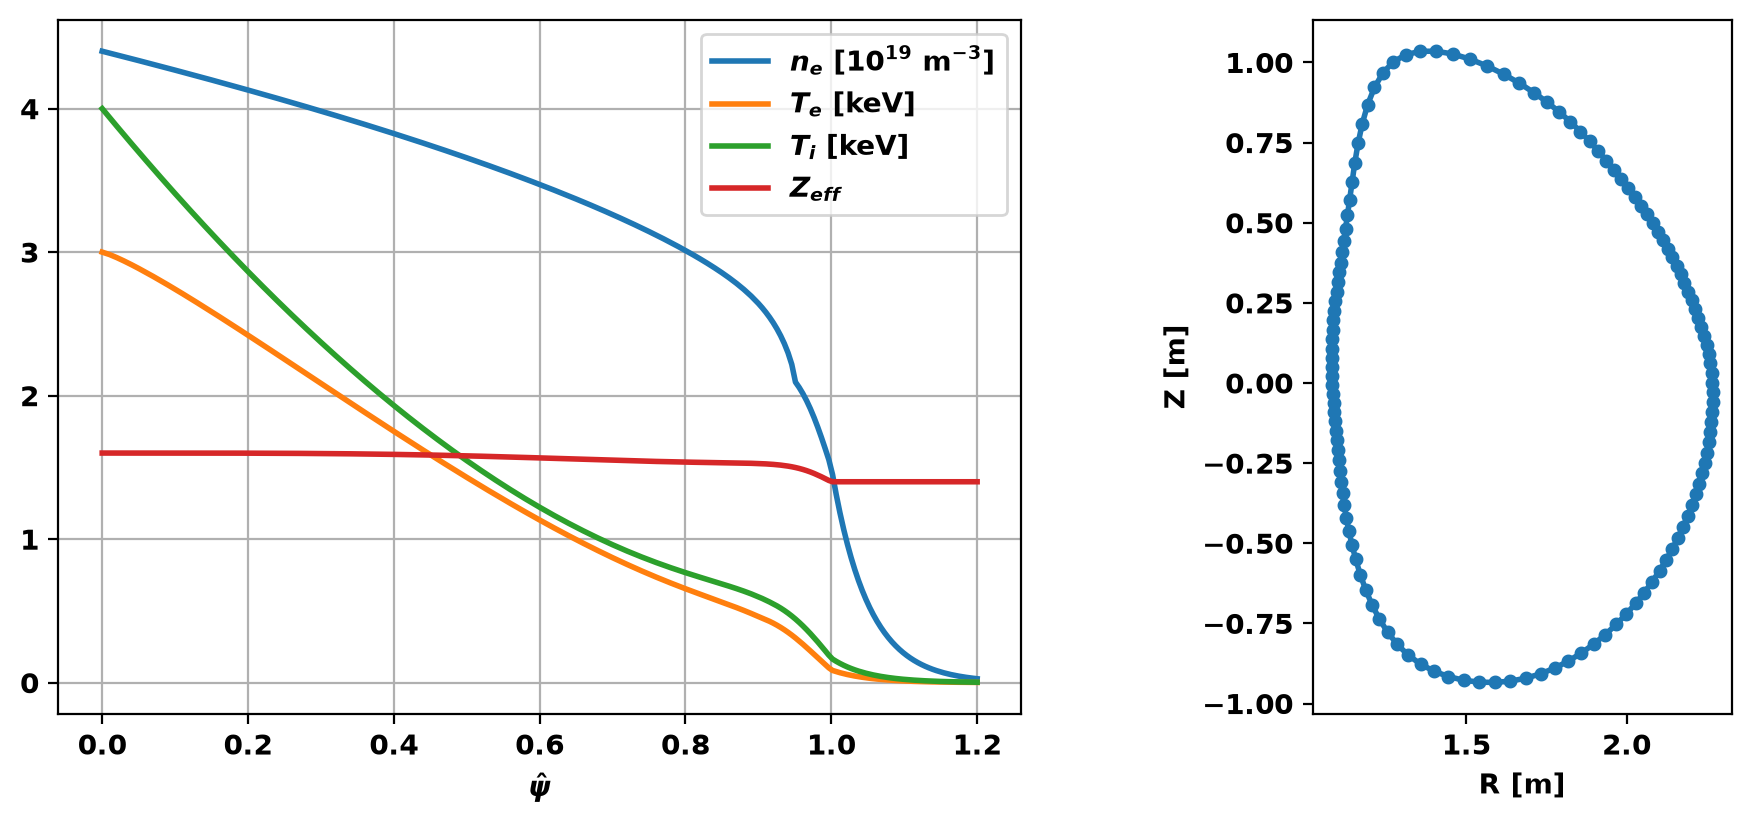

In [4]:
R0, B0, IP, Z_IMP = 1.7, -2.0, 1.3E6, 6.0
psi_n = np.r_[0.01*np.arange(90), np.linspace(0.9, 1.2, 60)]
xs = np.linspace(0.0, 1.0, 4001)
def prof(x, edge, ped, core, expin, expout, widthp, xphalf, sol=True):
    v = Hmode_profiles(edge=edge, ped=ped, core=core, rgrid=xs.size, expin=expin, expout=expout, widthp=widthp, xphalf=xphalf)
    out = np.interp(np.clip(x, 0.0, 1.0), xs, v)
    return np.where(x > 1.0, v[-1]*np.exp(-(x - 1.0)/0.05), out) if sol else out
ne = 1.E19*prof(psi_n, 1.5, 2.1, 4.4, 1.0, 0.58, 0.1, 1.0)
te = 1.E3*prof(psi_n, 0.088, 0.45, 3.0, 1.2, 1.5, 0.15, 0.98)
ti = 1.E3*prof(psi_n, 0.17, 0.55, 4.0, 1.0, 1.7, 0.16, 1.0)
zeff = prof(psi_n, 1.4, 1.5, 1.6, 3.6, 3.2, 0.1, 1.0, sol=False)
ni = ne*(Z_IMP - zeff)/(Z_IMP - 1.0)
kinetics = current_model.KineticProfiles(psi_n, ne, te, ni, ti, zeff, source='analytic L-mode profiles')
sources = current_model.SourceProfiles(psi_n, source='none')

lcfs16 = np.array([(-0.62, 0.087), (-0.6, 0.32), (-0.56, 0.6), (-0.43, 1.0), (-0.01, 0.92), (0.24, 0.69), (0.4, 0.47),
                   (0.49, 0.29), (0.56, 0.07), (0.56, -0.16), (0.48, -0.44), (0.3, -0.72), (-0.01, -0.92), (-0.38, -0.85),
                   (-0.56, -0.49), (-0.6, -0.21)]) + [R0, 0.0]
from scipy.interpolate import CubicSpline
c = lcfs16.mean(axis=0)
th = np.arctan2(lcfs16[:,1]-c[1], lcfs16[:,0]-c[0])
order = np.argsort(th)
th, pts = np.r_[th[order], th[order][0]+2*np.pi], np.vstack([lcfs16[order], lcfs16[order][:1]])
boundary = CubicSpline(th, pts, bc_type='periodic')(np.linspace(th[0], th[0]+2*np.pi, 128, endpoint=False))

fig, ax = plt.subplots(1,2,figsize=(10,4),constrained_layout=True)
ax[0].plot(psi_n, ne/1.E19, label=r'$n_e$ [$10^{19}$ m$^{-3}$]')
ax[0].plot(psi_n, te/1.E3, label=r'$T_e$ [keV]')
ax[0].plot(psi_n, ti/1.E3, label=r'$T_i$ [keV]')
ax[0].plot(psi_n, zeff, label=r'$Z_{eff}$')
ax[0].set_xlabel(r'$\hat{\psi}$'); ax[0].legend(); ax[0].grid(True)
ax[1].plot(boundary[:,0], boundary[:,1], '.-'); ax[1].set_aspect('equal'); ax[1].set_xlabel('R [m]'); ax[1].set_ylabel('Z [m]')

### The truth equilibrium
The truth is solved by the forward model of the helper package in its generation mode (no measurements; the Ip
target and the boundary points as isoflux targets, coil currents regularized toward zero), iterated to consistency
with the default current model at a bootstrap multiplier \f$ s_{bs} = 1 \f$. The first solve uses a peaked current
shape and the kinetic pressure as its starting profiles.

In [5]:
mesh_file = 'DIIID_mesh.h5'
vsc = {'F9A': 1.0, 'F9B': -1.0}
truth_fm = forward.ForwardModel(load_gs_mesh(mesh_file), R0*B0, None, boundary, settings=forward.ForwardSettings(vsc=vsc),
                                oft_env=myOFT, case_id='truth', ip=IP, generation_coil_reg=1.E-2)
a = 0.5*(lcfs16[:,0].max() - lcfs16[:,0].min())
truth_fm.gs.init_psi(0.5*(lcfs16[:,0].max() + lcfs16[:,0].min()), 0.0, a, 0.5*(lcfs16[:,1].max() - lcfs16[:,1].min())/a, 0.3)
xj = np.linspace(0.0, 1.0, 129)
p_kin = kinetics.thermal_pressure(xj)
initial_profiles = (xj, 1.E6*prof(xj, 0.0, 0.11, 2.4, 1.1, 1.7, 0.011, 0.98), p_kin)
model_settings = current_model.CurrentModelSettings(r0=R0)
truth = current_model.consistent_solve(truth_fm, kinetics, sources, {'s_bs': 1.0}, model_settings, label='truth',
                                       initial_profiles=initial_profiles)
print(truth.status, 'after', truth.passes, 'passes')
truth_gs = truth_fm.gs
truth_gs.print_info()


**** Loading OFT surface mesh

**** Generating surface grid level  1
  Generating boundary domain linkage


  Mesh statistics:
    Area         =  1.574E+01
    # of points  =   17411
    # of edges   =   52070
    # of cells   =   34660
    # of boundary points =     160
    # of boundary edges  =     160
    # of boundary cells  =     160
  Resolution statistics:
    hmin =  8.097E-04
    hrms =  3.450E-02
    hmax =  1.464E-01
  Surface grounded at vertex    1960


**** Creating Lagrange FE space
  Order  =    2
  Minlev =   -1



 Computing flux BC matrix 


 Inverting real matrix
   Time =    6.6354990000000004E-003


 Inverting real matrix
   Time =    1.5739999999999998E-005
 Inverting real matrix
   Time =    3.6100000000000002E-006


consistent after 9 passes
Equilibrium Statistics:
  Topology                =   Diverted
  Toroidal Current [A]    =    1.3000E+06
  Current Centroid [m]    =    1.667 -0.013
  Magnetic Axis [m]       =    1.718 -0.026
  Elongation              =    1.665 (U:  1.809, L:  1.520)
  Triangularity           =    0.397 (U:  0.644, L:  0.150)
  Plasma Volume [m^3]     =   17.783
  q_0, q_95               =   -1.013 -3.695
  Plasma Pressure [Pa]    =   Axis:  4.5310E+04, Peak:  4.5310E+04
  Stored Energy [J]       =    3.7503E+05
  <Beta_pol> [%]          =   33.4003
  <Beta_tor> [%]          =    0.8587
  <Beta_n>   [%]          =    0.7901
  Diamagnetic flux [Wb]   =   -3.1547E-02
  Toroidal flux [Wb]      =   -3.7761E+00
  l_i                     =    1.1641


### Synthetic measurements
We place 40 flux loops and 60 poloidal-field probes (alternately 4 cm long along and 3 cm long across their
direction) 3 cm inside the limiter, take every coil current, the plasma current, and a 16-chord MSE fan with made-up
geometry coefficients, and evaluate them on the truth with the synthetic diagnostics. Each measurement gets an
uncertainty and Gaussian noise of that size. The E-coils are held at their measured current, two F-coils are left
free, the other coils are fitted to their measurements. The MSE group is declared E_r-corrected, so it is a fit
constraint.

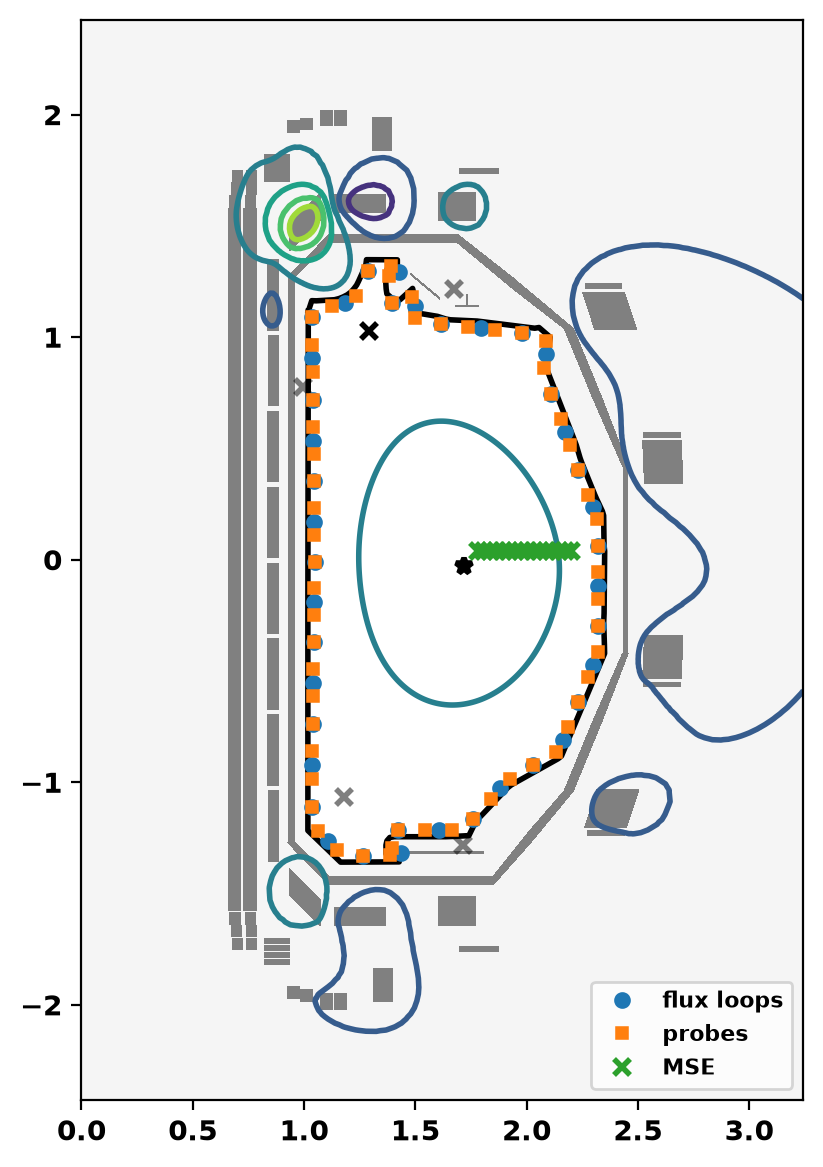

In [6]:
lim = np.asarray(truth_gs.lim_contour, float)
seg = np.r_[0.0, np.cumsum(np.hypot(*np.diff(lim, axis=0).T))]
def on_limiter(n, inset):
    s = np.linspace(0.0, seg[-1], n, endpoint=False)
    p = np.column_stack((np.interp(s, seg, lim[:,0]), np.interp(s, seg, lim[:,1])))
    t = np.column_stack((np.interp(s+1.E-3, seg, lim[:,0]), np.interp(s+1.E-3, seg, lim[:,1]))) - p
    t /= np.hypot(t[:,0], t[:,1])[:,None]
    d = np.array([1.75, 0.0]) - p
    d /= np.hypot(d[:,0], d[:,1])[:,None]
    return p + inset*d, t
fl, _ = on_limiter(40, 0.03)
pr, tan = on_limiter(60, 0.03)
n_mse = 16
coef = np.column_stack((np.linspace(0.70, 0.95, n_mse), np.zeros(n_mse), np.zeros(n_mse), np.full(n_mse, 1.5E-6),
                        np.full(n_mse, 0.05), np.linspace(0.2, 0.4, n_mse), -np.linspace(0.6, 0.8, n_mse),
                        np.full(n_mse, 1.E-7), np.zeros(n_mse)))
geometry = {'flux_loop': {'r': fl[:,0], 'z': fl[:,1]},
            'bpol_probe': {'r': pr[:,0], 'z': pr[:,1], 'direction_r': tan[:,0], 'direction_z': tan[:,1],
                           'length': np.where(np.arange(60) % 2 == 0, 0.04, -0.03)},
            'pf_current': {'coil_names': list(truth_gs.coil_sets)},
            'mse': {'r': np.linspace(1.78, 2.20, n_mse), 'z': np.full(n_mse, 0.04), 'coefficients': coef}}
roles = {n: ('held' if n.startswith('E') else ('free' if n in ('F8A', 'F8B') else 'fitted')) for n in truth_gs.coil_sets}
true_values = {'flux_loop': diagnostics.flux_loop(truth_gs, geometry['flux_loop']).value,
               'bpol_probe': diagnostics.bpol_probe(truth_gs, geometry['bpol_probe']).value,
               'pf_current': diagnostics.pf_current(truth_gs, geometry['pf_current']).value,
               'ip': diagnostics.ip(truth_gs).value,
               'mse': diagnostics.mse(truth_gs, geometry['mse'], quantity='tan_polarisation_angle').value}
sigma = {'flux_loop': np.maximum(0.01*np.abs(true_values['flux_loop']), 2.E-3),
         'bpol_probe': np.maximum(0.02*np.abs(true_values['bpol_probe']), 2.E-3),
         'pf_current': np.maximum(0.01*np.abs(true_values['pf_current']), 200.0),
         'ip': np.array([5.E-3*IP]), 'mse': np.full(n_mse, 3.5E-3)}
meta = {'flux_loop': {'coils_form': 'absolute', 'absolute_offset': 0.0},
        'mse': {'er_corrected': True, 'quantity': 'tan_polarisation_angle'}}
rng = np.random.default_rng(20261120)
groups = {}
for name, v in true_values.items():
    v = np.asarray(v, float)
    measured = v + rng.standard_normal(v.size)*sigma[name]
    if name == 'pf_current':   # held coils are held at their measurement: give them the true value
        measured = np.where([roles[n] == 'held' for n in geometry['pf_current']['coil_names']], v, measured)
    groups[name] = ConstraintGroup(name=name, labels=['{0}_{1}'.format(name, i) for i in range(v.size)], measured=measured,
                                   sigma=sigma[name], valid=np.isfinite(v), geometry=geometry.get(name, {}),
                                   meta=dict(sigma_model='synthetic example', **meta.get(name, {})))
measurements = MeasurementSet('DIII-D-like synthetic example', 3.0, 0.01, groups)

fig, ax = plt.subplots(1,1,figsize=(4,6),constrained_layout=True)
truth_gs.plot_machine(fig, ax)
truth_gs.plot_psi(fig, ax, normalized=False)
ax.plot(fl[:,0], fl[:,1], 'o', ms=4, label='flux loops')
ax.plot(pr[:,0], pr[:,1], 's', ms=3, label='probes')
ax.plot(geometry['mse']['r'], geometry['mse']['z'], 'x', label='MSE')
ax.legend(loc='lower right', fontsize=8)

## Reconstruction
### Set up the reconstruction
The class takes the OFT environment, the mesh file and the device description: the vertical stability coil pairing
and the reference major radius of the current model. Its settings are the helper package's own settings objects
with their own defaults; here we free only the bootstrap multiplier \f$ s_{bs} \f$ (prior 1 +/- 0.5). Because the
plasma current is fitted by default (`ip_target='fitted'`), the Ip target joins as a second parameter.

The inputs of the slice are collected in a
\ref OpenFUSIONToolkit.TokaMaker.reconstruction.kinetic_slice_data "kinetic_slice_data": the measurements, the
kinetic profiles and sources, the anchor boundary (here the truth's own last closed flux surface), \f$ F_0 \f$, the
starting flux on the mesh nodes (here the truth's) with the profiles of the first solve, and the starting parameters
(\f$ s_{bs} = 1.3 \f$, deliberately wrong).

In [7]:
recon = kinetic_reconstruction(myOFT, mesh_file, machine={'name': 'DIII-D-like', 'vsc': vsc, 'r0': R0},
                               fit_settings=fit.FitSettings(free=('s_bs',)))
data = kinetic_slice_data(measurements, kinetics, sources, np.asarray(truth_gs.trace_surf(0.999)), R0*B0,
                          start=np.array(truth_gs.get_psi(False)), coil_roles=roles,
                          initial_profiles=initial_profiles, params0={'s_bs': 1.3})

### Run the fit
The mode is required: `'slice'` is the only mode implemented.

In [8]:
result = recon.run(data, measurements.time, mode='slice')
print('status:', result.status)
print('solves:', result.record['n_solves'], ' wall time [s]:', result.record['wall_s'])
ip_rel_true = IP/measurements.groups['ip'].measured[0] - 1.0
for name, value, sig in zip(result.free, result.theta, result.sigma):
    true = {'s_bs': 1.0, 'ip_rel': ip_rel_true}[name]
    print('{0:8s} fit = {1:9.5f} +/- {2:8.5f}   truth = {3:9.5f}   (fit - truth)/sigma = {4:5.2f}'.format(name, value, sig, true, (value - true)/sig))
print('data chi^2 = {0:.1f} for {1:.1f} degrees of freedom'.format(result.chi2['data'], result.chi2['dof']))


**** Loading OFT surface mesh

**** Generating surface grid level  1
  Generating boundary domain linkage
  Mesh statistics:
    Area         =  1.574E+01
    # of points  =   17411
    # of edges   =   52070
    # of cells   =   34660
    # of boundary points =     160
    # of boundary edges  =     160
    # of boundary cells  =     160
  Resolution statistics:
    hmin =  8.097E-04
    hrms =  3.450E-02
    hmax =  1.464E-01
  Surface grounded at vertex    1960


**** Creating Lagrange FE space
  Order  =    2
  Minlev =   -1

 Computing flux BC matrix 


 Inverting real matrix
   Time =    3.3593160000000002E-003


status: converged
solves: 104  wall time [s]: 128.16
s_bs     fit =   0.98436 +/-  0.06777   truth =   1.00000   (fit - truth)/sigma = -0.23
ip_rel   fit =  -0.00002 +/-  0.00194   truth =  -0.00096   (fit - truth)/sigma =  0.49
data chi^2 = 104.2 for 122.7 degrees of freedom


### Fit quality
The normalized residuals \f$ (m - v)/\sigma \f$ of every channel used in the fit, from the fit record.

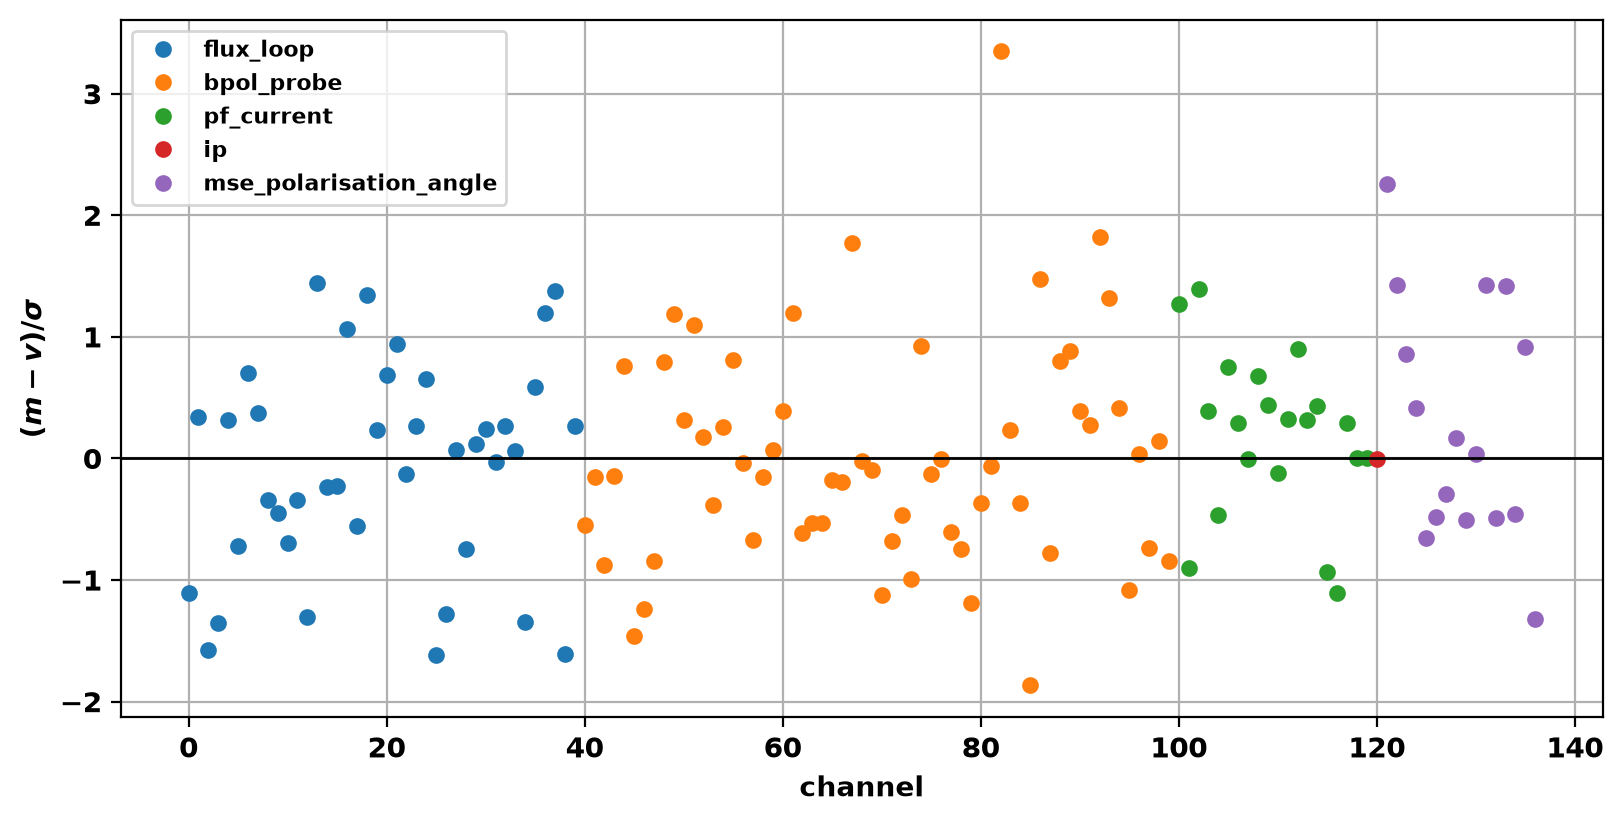

In [9]:
cons = result.record['constraints']
fig, ax = plt.subplots(1,1,figsize=(8,4),constrained_layout=True)
i0 = 0
for name, rows in cons.items():
    r = np.array([(row['reconstructed'] - row['measured'])*row['weight']/row['measured_error_upper'] for row in rows])
    ax.plot(np.arange(i0, i0 + r.size), r, 'o', ms=4, label=name)
    i0 += r.size
ax.axhline(0.0, color='k', lw=1)
ax.set_xlabel('channel'); ax.set_ylabel(r'$(m - v)/\sigma$'); ax.grid(True); ax.legend(fontsize=8)

### q and current profiles against the truth
The fitted equilibrium is the solver's state at the fit's final point; the truth is the synthetic equilibrium. The
current density is the flux-surface-averaged \f$ \langle j_\phi \rangle \f$ of the current model at the final
point.

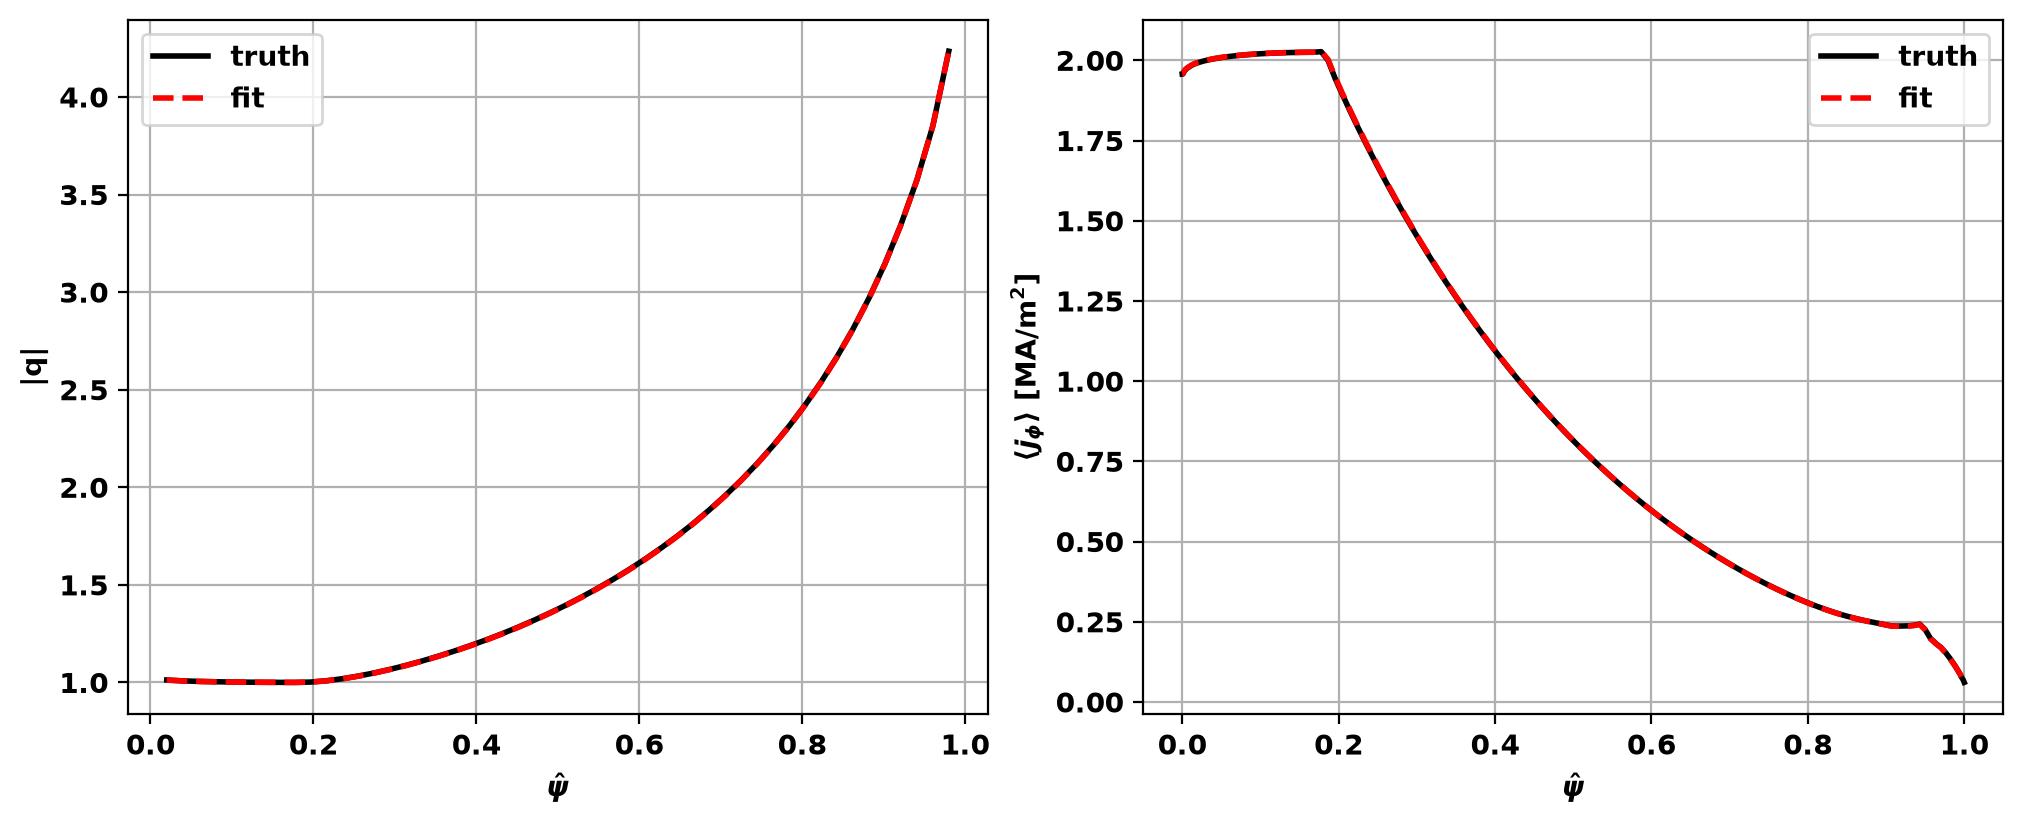

In [10]:
psi_q = np.linspace(0.02, 0.98, 50)
_, q_truth, _, _, _, _ = truth_gs.get_q(psi=psi_q)
_, q_fit, _, _, _, _ = recon.gs.get_q(psi=psi_q)
asm_truth = truth.assembly
asm_fit = result.record['center']['res'].assembly
fig, ax = plt.subplots(1,2,figsize=(10,4),constrained_layout=True)
ax[0].plot(psi_q, np.abs(q_truth), 'k-', label='truth')
ax[0].plot(psi_q, np.abs(q_fit), 'r--', label='fit')
ax[0].set_xlabel(r'$\hat{\psi}$'); ax[0].set_ylabel('|q|'); ax[0].grid(True); ax[0].legend()
ax[1].plot(asm_truth['x'], np.asarray(asm_truth['jphi'])/1.E6, 'k-', label='truth')
ax[1].plot(asm_fit['x'], np.asarray(asm_fit['jphi'])/1.E6, 'r--', label='fit')
ax[1].set_xlabel(r'$\hat{\psi}$'); ax[1].set_ylabel(r'$\langle j_\phi \rangle$ [MA/m$^2$]'); ax[1].grid(True); ax[1].legend()

### Save the fitted equilibrium
The g-file is written with TokaMaker's own writer and carries the full pressure (the separatrix pressure is added
through `lcfs_pressure`). Every setting and diagnostic of the fit is in `result.record`.

In [11]:
print(result.save_geqdsk('kinetic_fit.geqdsk'))

Saving gEQDSK: kinetic_fit.geqdsk
{'file': 'kinetic_fit.geqdsk', 'p_sep': 591.5219508279765, 'pressure_frame': 'full', 'note': 'PRES = solver pressure + p_sep (TokaMaker lcfs_pressure); PPRIME unchanged'}
